## Import Libraries and Configuration Settings

In [ ]:
!pip install numpy pandas matplotlib seaborn scikit-learn imbalanced-learn

import os
from collections import Counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from imblearn.over_sampling import SMOTE
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 824

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [imblearn]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


## Data Understanding

In [ ]:
train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')
sample_submission = pd.read_csv('data/sample_submission.csv')

print(f'Format submisi:\n{sample_submission.head()}')

print(f'Panjang train dataset = {len(train_df)}')
print(f'Panjang test dataset = {len(test_df)}')

train_df.describe()
# test_df.describe()

# print(train_df.head())

Format submisi:
         id  is_canceled
0  5cb6f473            0
1  c06b4ab3            0
2  22bf3fc3            0
3  25408a48            0
4  621586b6            0
Panjang train dataset = 27373
Panjang test dataset = 6844


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.000000,24338.000000,27373.000000,27373.000000,26291.000000,26250.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
mean,1.845242,0.117388,0.814854,2.206517,0.030200,85.379429,2023.820115,7.399664,15.537537,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,0.517974,0.425761,0.875146,1.421603,0.171142,85.969638,0.384099,3.074788,8.773321,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,58.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,126.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,448.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,58.000000,9.165000e+06,5.000000,1.000000


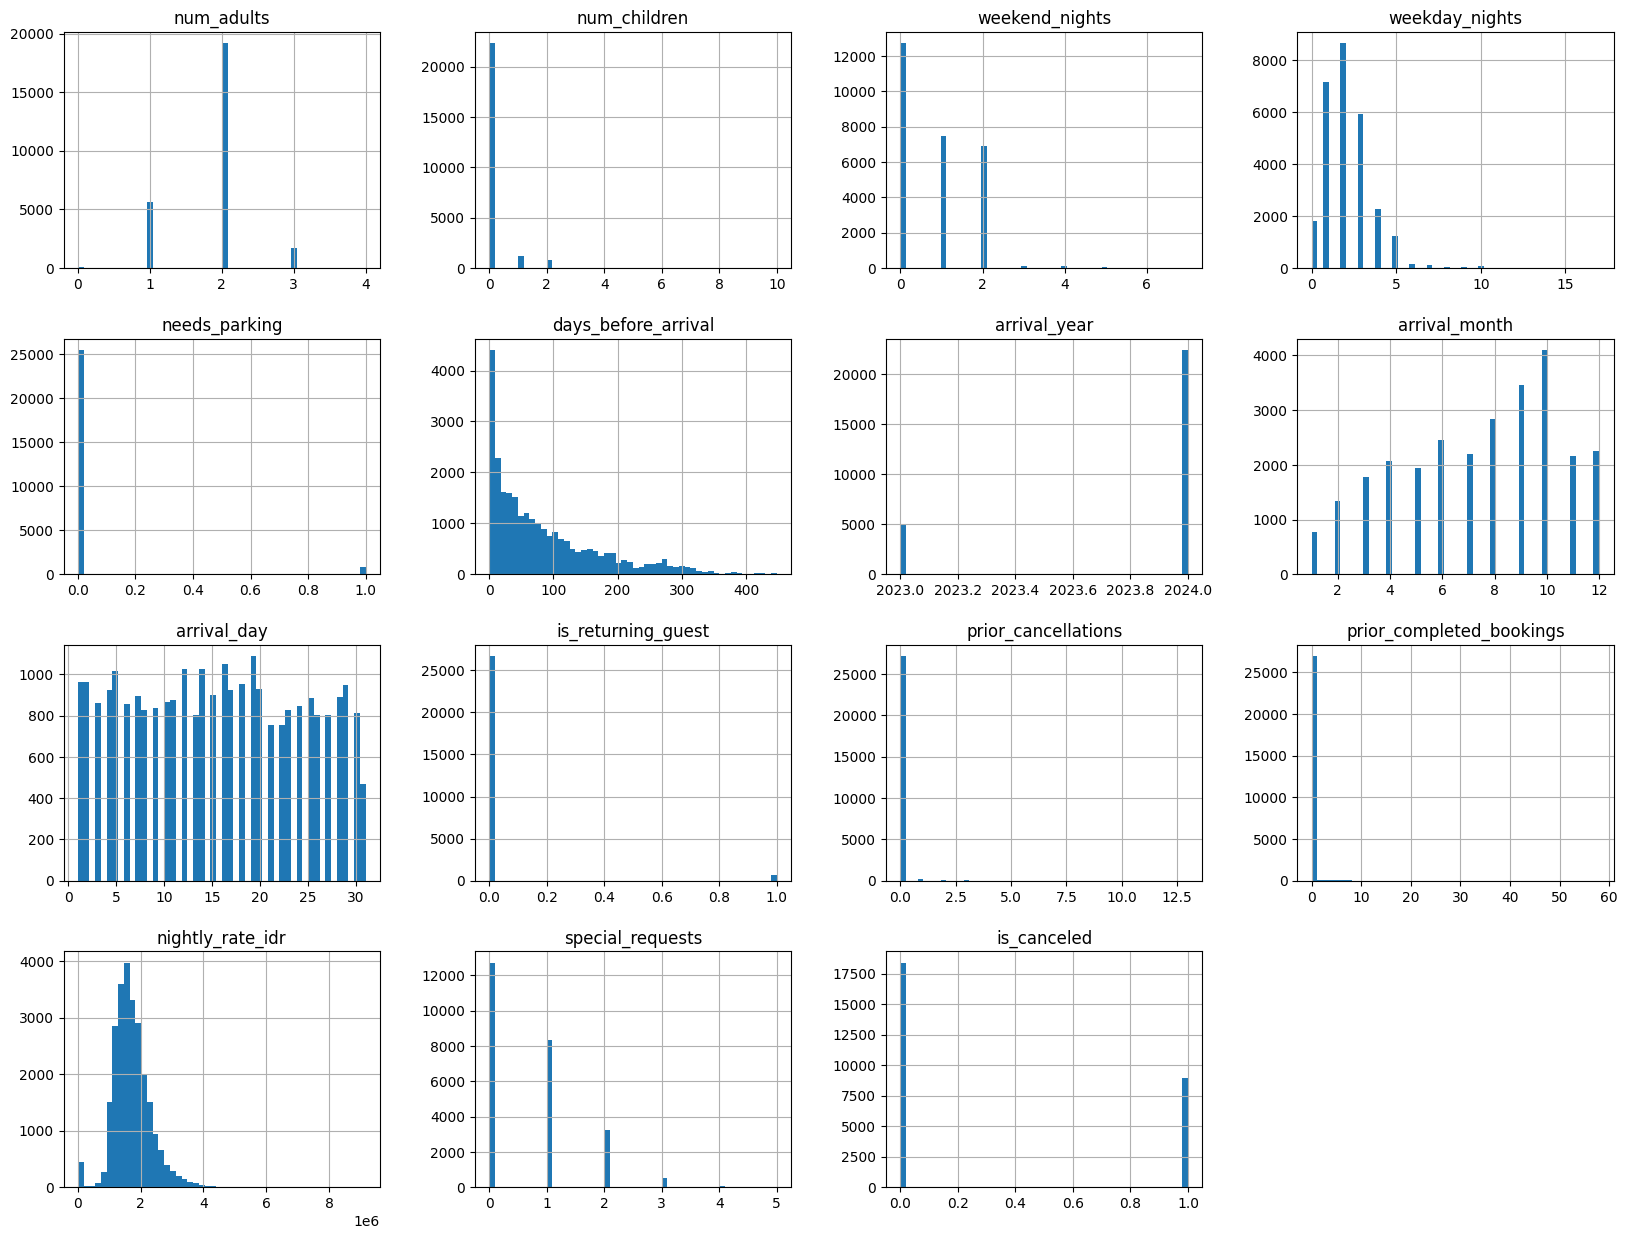

In [ ]:
train_df.hist(bins=50, figsize=(20,15))
plt.show()

In [ ]:
print('Standard Correlation Coefficient (Pearson\'s r)')

corr_matrix = train_df.corr(numeric_only=True)
corr_matrix['is_canceled'].sort_values(ascending = False)

Standard Correlation Coefficient (Pearson's r)


is_canceled                 1.000000
days_before_arrival         0.440316
arrival_year                0.179826
nightly_rate_idr            0.134092
weekday_nights              0.097226
num_adults                  0.088446
weekend_nights              0.060797
num_children                0.030856
arrival_day                 0.020005
arrival_month              -0.015912
prior_cancellations        -0.035006
prior_completed_bookings   -0.058894
needs_parking              -0.085504
is_returning_guest         -0.107207
special_requests           -0.257996
Name: is_canceled, dtype: float64

## Data Cleaning

### Missing Value Handling

In [ ]:
# referensi: https://www.kaggle.com/code/alexisbcook/handling-missing-values

# ========== MISSING VALUE HANDLING ==========
# ===== Show missing values =====
# 1. Train DF
print('Train DF Missing Values')
total_cells = np.prod(train_df.shape)
missing_values_count = train_df.isnull().sum()
# print(missing_values_count)
total_missing = missing_values_count.sum()
percent_missing = (total_missing/total_cells) * 100
print(f'Total missing values = {missing_values_count.sum()}. Missing percentage = {percent_missing}%\n\n')

# 2. Test DF
print('Test DF Missing Values')
total_cells = np.prod(test_df.shape)
missing_values_count = test_df.isnull().sum()
# print(missing_values_count)
total_missing = missing_values_count.sum()
percent_missing = (total_missing/total_cells) * 100
print(f'Total missing values = {missing_values_count.sum()}. Missing percentage = {percent_missing}%\n\n')

# cek hasil jika drop missing values di train_df
train_df_cleaned = train_df.copy()
train_df_cleaned = train_df_cleaned.dropna()
print(f'Training dataset sebelum drop missing vals: {len(train_df)}')
print(f'Training dataset setelah drop missing vals: {len(train_df_cleaned)}\n\n')

# fungsi untuk mengisi nilai kosong pada dataframe
def clean_df(df, columns, method, train_ref=None):
    if df is None:
        print('df invalid')
    if columns is None:
        print('columns invalid')

    ref = train_ref if train_ref is not None else df

    if method == 'median' or method == 'mode':
        for col in columns:
            if method == 'median':
                filler = ref[col].median()
            if method == 'mode':
                filler = ref[col].mode()[0]
            df[col] = df[col].fillna(filler)
        return df
    else:
        print('method invalid')
        return None


# ===== Clean missing values =====
# 1. Train DF
train_df_cleaned = train_df.copy() # reset dataframe training
numerical_columns = ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 
    'days_before_arrival', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 
    'special_requests']
train_df_cleaned = clean_df(train_df_cleaned, numerical_columns, 'median')

categorical_columns = ['needs_parking', 'arrival_year', 'arrival_month', 'arrival_day', 
    'is_returning_guest', 'meal_package', 'room_category', 'booking_channel']
train_df_cleaned = clean_df(train_df_cleaned, categorical_columns, 'mode')
print(f'Sisa missing train_df values setelah cleaning = {train_df_cleaned.isnull().sum().sum()}')
print(f'Panjang train_df_cleaned setelah cleaning = {len(train_df_cleaned)}')


# 2. Test DF
test_df_cleaned = test_df.copy()
test_df_cleaned = clean_df(test_df_cleaned, numerical_columns, 'median', test_df)
test_df_cleaned = clean_df(test_df_cleaned, categorical_columns, 'mode', test_df)

print(f'Sisa missing test_df values setelah cleaning = {test_df_cleaned.isnull().sum().sum()}')
print(f'Panjang test_df_cleaned setelah cleaning = {len(test_df_cleaned)}\n')

Train DF Missing Values
Total missing values = 13349. Missing percentage = 2.566685958310821%


Test DF Missing Values
Total missing values = 3281. Missing percentage = 2.6633222936554324%


Training dataset sebelum drop missing vals: 27373
Training dataset setelah drop missing vals: 16636


Sisa missing train_df values setelah cleaning = 0
Panjang train_df_cleaned setelah cleaning = 27373
Sisa missing test_df values setelah cleaning = 0
Panjang test_df_cleaned setelah cleaning = 6844



> Karena jumlah data yang terbuang cukup banyak, maka baris dengan missing value tidak sebaiknya dihapus, melainkan diisi dengan median atau modus. 

### Duplicate and Invalid Data Handling

In [ ]:
# ========== DUPLICATE VALUES HANDLING ==========
print(f'Nilai ganda training = {train_df.duplicated().sum()}\n\n')


# ========== INVALID VALUE HANDLING ==========
# 1. Train DF
# cek nilai negatif
numeric_train_df = train_df_cleaned.select_dtypes(include='number')
print(f'Jumlah nilai negatif pada data train: {(numeric_train_df<0).sum().sum()}')

# cek nilai yang tidak seharusnya 0
no_adults = (train_df_cleaned['num_adults'] == 0)
print(f'Banyak pesanan tanpa orang dewasa = {no_adults.sum()}')
no_nights = ((train_df_cleaned['weekend_nights'] + train_df_cleaned['weekday_nights']) == 0)
print(f'Banyak pesanan dengan jumlah malam 0 = {no_nights.sum()}')

# cek tanggal invalid
date_df = train_df_cleaned[['arrival_year', 'arrival_month', 'arrival_day']].rename(
    columns={'arrival_year': 'year', 'arrival_month': 'month', 'arrival_day': 'day'}
)
invalid_dates = pd.to_datetime(date_df, errors='coerce').isna()
print(f"Banyak tanggal invalid: {invalid_dates.sum()}")

# hapus data invalid
train_df_cleaned = train_df_cleaned[(numeric_train_df >= 0).all(axis=1)].reset_index(drop=True)
valid_mask = (
    (~no_adults) &
    (~no_nights) &
    (~invalid_dates)
)

train_df_cleaned = train_df_cleaned[valid_mask].reset_index(drop=True)
print(f'Panjang train_df_cleaned setelah hapus data invalid = {len(train_df_cleaned)}')

# 2. Test DF
# cek nilai negatif
numeric_test_df = test_df_cleaned.select_dtypes(include='number')
print(f'Jumlah nilai negatif pada data test: {(numeric_test_df<0).sum().sum()}')

# cek nilai yang tidak seharusnya 0
no_adults = (test_df_cleaned['num_adults'] == 0)
print(f'Banyak pesanan tanpa orang dewasa = {no_adults.sum()}')
no_nights = ((test_df_cleaned['weekend_nights'] + test_df_cleaned['weekday_nights']) == 0)
print(f'Banyak pesanan dengan jumlah malam 0 = {no_nights.sum()}')

# cek tanggal invalid
date_df = test_df_cleaned[['arrival_year', 'arrival_month', 'arrival_day']].rename(
    columns={'arrival_year': 'year', 'arrival_month': 'month', 'arrival_day': 'day'}
)
invalid_dates = pd.to_datetime(date_df, errors='coerce').isna()
print(f"Banyak tanggal invalid: {invalid_dates.sum()}")

# isi data invalid dengan median
# Karena untuk test_df, baris tidak boleh dihapus
median_train_adults = train_df_cleaned['num_adults'].median()
test_df_cleaned.loc[no_adults, 'num_adults'] = median_train_adults

median_weekday_nights = train_df_cleaned['weekday_nights'].median()
test_df_cleaned.loc[no_nights, 'weekday_nights'] = median_weekday_nights

print(f'Panjang test_df_cleaned setelah fill data invalid = {len(test_df_cleaned)}')

Nilai ganda training = 0


Jumlah nilai negatif pada data train: 0
Banyak pesanan tanpa orang dewasa = 106
Banyak pesanan dengan jumlah malam 0 = 64
Banyak tanggal invalid: 0
Panjang train_df_cleaned setelah hapus data invalid = 27203
Jumlah nilai negatif pada data test: 0
Banyak pesanan tanpa orang dewasa = 22
Banyak pesanan dengan jumlah malam 0 = 9
Banyak tanggal invalid: 0
Panjang test_df_cleaned setelah fill data invalid = 6844


> Di sisi lain, jumlah data invalid cukup sedikit (< 200 baris), sehingga dihapus tidak masalah.

## Data Transformation

### Categorical Data Encoding

In [ ]:
# encoding categorical jadi numerical
train_df_encoded = train_df_cleaned.copy()
test_df_encoded = test_df_cleaned.copy()

ordinal_maps = {
    'meal_package': {'Room Only': 1, 'Breakfast': 2, 'Half Board': 3, 'Full Board': 4}
}
for col, mapping in ordinal_maps.items():
    train_df_encoded[col] = train_df_encoded[col].map(mapping)
    test_df_encoded[col] = test_df_encoded[col].map(mapping)

# reference: https://www.kaggle.com/discussions/getting-started/114797
# room category harus dilakukan one hot encoding karena "show no order or quality"
# booking channel diasumsikan juga demikian
train_df_encoded = pd.get_dummies(train_df_encoded, columns=['room_category', 'booking_channel'], drop_first=True)
test_df_encoded = pd.get_dummies(test_df_encoded, columns=['room_category', 'booking_channel'], drop_first=True)

print("Hasil encoding train_df:")
print(train_df_encoded.head(5))
print("Hasil encoding test_df:")
print(test_df_encoded.head(5))

Hasil encoding train_df:
         id  num_adults  num_children  weekend_nights  weekday_nights  \
0  57152f82         2.0           0.0               1               2   
1  af2ec71b         2.0           0.0               2               1   
2  5d5469ab         3.0           0.0               1               2   
3  d2df0369         2.0           1.0               2               1   
4  91d253db         2.0           0.0               0               1   

   meal_package  needs_parking  days_before_arrival  arrival_year  \
0             2            0.0                 88.0          2024   
1             3            0.0                120.0          2023   
2             2            0.0                209.0          2024   
3             2            0.0                 93.0          2024   
4             1            0.0                 14.0          2024   

   arrival_month  ...  room_category_Type B  room_category_Type C  \
0              4  ...                  True         

### Scaling \(Standardization\)

In [ ]:
# Gunakan StandardScaler() dengan asumsi data numerik terdistribusi normal
# reference: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

scaler = StandardScaler()
train_df_encoded[numerical_columns] = scaler.fit_transform(train_df_encoded[numerical_columns])
test_df_encoded[numerical_columns] = scaler.fit_transform(test_df_encoded[numerical_columns])

print(train_df_encoded.head())
print(test_df_encoded.head())

train_df_encoded.describe()
test_df_encoded.describe()

         id  num_adults  num_children  weekend_nights  weekday_nights  \
0  57152f82    0.285848     -0.251437        0.209944       -0.148402   
1  af2ec71b    0.285848     -0.251437        1.352625       -0.853182   
2  5d5469ab    2.291504     -0.251437        0.209944       -0.148402   
3  d2df0369    0.285848      2.342362        1.352625       -0.853182   
4  91d253db    0.285848     -0.251437       -0.932737       -0.853182   

   meal_package  needs_parking  days_before_arrival  arrival_year  \
0             2            0.0             0.044166          2024   
1             3            0.0             0.423374          2023   
2             2            0.0             1.478044          2024   
3             2            0.0             0.103418          2024   
4             1            0.0            -0.832750          2024   

   arrival_month  ...  room_category_Type B  room_category_Type C  \
0              4  ...                  True                 False   
1       

,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests
count,6.844000e+03,6.844000e+03,6.844000e+03,6.844000e+03,6844.000000,6844.000000,6.844000e+03,6844.000000,6844.000000,6844.000000,6844.000000,6.844000e+03,6.844000e+03,6.844000e+03,6.844000e+03
mean,-1.152400e-16,2.309991e-17,-4.983351e-17,1.391185e-16,1.945500,0.032291,2.180216e-17,2023.818235,7.401812,15.702659,0.027323,2.076396e-18,3.633693e-17,-2.086778e-16,4.360432e-17
std,1.000073e+00,1.000073e+00,1.000073e+00,1.000073e+00,0.459474,0.176785,1.000073e+00,0.385679,3.050240,8.681514,0.163035,1.000073e+00,1.000073e+00,1.000073e+00,1.000073e+00
min,-1.700637e+00,-2.657692e-01,-9.276610e-01,-1.603002e+00,1.000000,0.000000,-9.979654e-01,2023.000000,1.000000,1.000000,0.000000,-7.072566e-02,-9.489446e-02,-3.114792e+00,-7.848437e-01
25%,2.893030e-01,-2.657692e-01,-9.276610e-01,-8.770261e-01,2.000000,0.000000,-7.726737e-01,2024.000000,5.000000,8.000000,0.000000,-7.072566e-02,-9.489446e-02,-6.190263e-01,-7.848437e-01
50%,2.893030e-01,-2.657692e-01,2.368496e-01,-1.510505e-01,2.000000,0.000000,-3.220902e-01,2024.000000,8.000000,16.000000,0.000000,-7.072566e-02,-9.489446e-02,-1.195086e-01,-7.848437e-01
75%,2.893030e-01,-2.657692e-01,1.401360e+00,5.749252e-01,2.000000,0.000000,4.367874e-01,2024.000000,10.000000,23.000000,0.000000,-7.072566e-02,-9.489446e-02,4.729852e-01,4.965185e-01
max,4.269182e+00,7.219517e+00,6.059403e+00,1.073858e+01,4.000000,1.000000,4.254890e+00,2024.000000,12.000000,31.000000,1.000000,2.919720e+01,2.755270e+01,7.276636e+00,5.621967e+00


### Imbalanced Data Handling

In [ ]:
# Gunakan SMOTE untuk menambah data class yang imba
# hanya terapkan untuk training dataset
# Pisahkan X dan y
X_train_encoded = train_df_encoded.drop(columns=['is_canceled', 'id']).copy()
y_train_encoded = train_df_encoded['is_canceled'].copy()

X_train_balanced = X_train_encoded
y_train_balanced = y_train_encoded

print(f"Data sebelum SMOTE: {y_train_balanced.value_counts().to_dict()}")

# Terapkan SMOTE
smote = SMOTE(random_state=RANDOM_STATE)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_encoded, y_train_encoded)

print(f"Data setelah SMOTE: {y_train_balanced.value_counts().to_dict()}")

Data sebelum SMOTE: {0: 18268, 1: 8935}
Data setelah SMOTE: {1: 18268, 0: 18268}


## Feature Selection

In [ ]:
# Feature selection sebenarnya ada filter dan wrapper, tapi untuk ini dilakukan filter dulu
# TODO: tambahkan metode feature selection tipe wrapper saat modeling

selector = SelectKBest(score_func=f_classif, k=10)
X_train_selected = selector.fit_transform(X_train_balanced, y_train_balanced)

feature_summary = pd.DataFrame({
    'Feature': X_train_balanced.columns,
    'Score': selector.scores_
}).sort_values(by='Score', ascending=False).reset_index(drop=True)

print("Features score (sorted):")
print(feature_summary)

selected_features = feature_summary.head(15)['Feature'].tolist()
X_train_final = X_train_balanced[selected_features]

X_test_final = test_df_encoded[selected_features]

Features score (sorted):
                                Feature        Score
0                   days_before_arrival  8181.867652
1                      special_requests  3390.638722
2                          arrival_year  1501.950908
3                      nightly_rate_idr   706.318961
4                    is_returning_guest   659.003064
5   booking_channel_Online Travel Agent   577.382680
6             booking_channel_Corporate   553.534144
7                         needs_parking   376.244815
8                            num_adults   348.102839
9                        weekday_nights   337.318398
10        booking_channel_Complimentary   289.500918
11             prior_completed_bookings   194.192925
12                       weekend_nights   134.870212
13                  prior_cancellations    69.925067
14                         num_children    38.969722
15                 room_category_Type G    36.604861
16        booking_channel_Offline Agent    30.063945
17                   

## Dimensionality Reduction

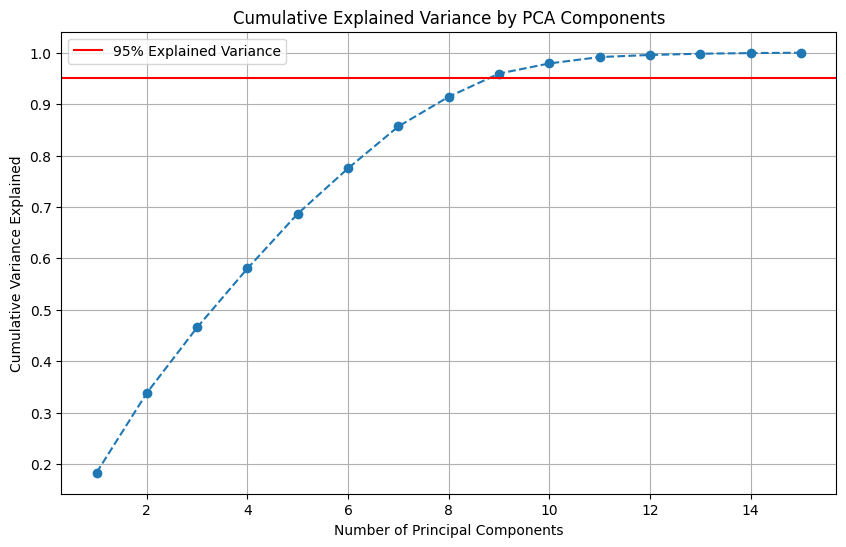

Dimensi sebelum PCA (hasil feature selection): 15
Dimensi setelah PCA (mempertahankan 95% varians): 9


In [ ]:
# Jika dataset memiliki jumlah fitur yang besar, reduksi dimensi dapat digunakan untuk mengurangi dimensi tanpa
# kehilangan informasi penting. Teknik seperti Principal Component Analysis (PCA) sering digunakan pada tahap ini.

pca_eval = PCA(random_state=RANDOM_STATE)
pca_eval.fit(X_train_final)

cumulative_variance = np.cumsum(pca_eval.explained_variance_ratio_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=0.95, color='r', linestyle='-', label='95% Explained Variance')
plt.title('Cumulative Explained Variance by PCA Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Variance Explained')
plt.legend()
plt.grid(True)
plt.show()

pca_final = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_train_pca = pca_final.fit_transform(X_train_final)

print(f"Dimensi sebelum PCA (hasil feature selection): {X_train_final.shape[1]}")
print(f"Dimensi setelah PCA (mempertahankan 95% varians): {X_train_pca.shape[1]}")

X_test_pca = pca_final.transform(X_test_final)

## Modeling and Validation

In [10]:
# ===== Import Model Logistic Regression From Scratch =====
from src.logistic_regression import LogisticRegression

print("LogisticRegression class berhasil di-import dari src/logistic_regression.py")

LogisticRegression class berhasil di-import dari src/logistic_regression.py


In [11]:
# ===== Train-Validation Split (Original vs SMOTE Tracking) =====
n_orig = len(X_train_encoded)
is_orig = np.arange(len(y_train_balanced)) < n_orig

# Jaga proporsi label target sekaligus baris asli vs sintetis
strat_key = np.asarray(y_train_balanced).astype(int) * 2 + is_orig.astype(int)
X_tr, X_val, y_tr, y_val, orig_tr, orig_val = train_test_split(
    X_train_pca,
    y_train_balanced,
    is_orig,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=strat_key,
)
X_tr, X_val = np.asarray(X_tr), np.asarray(X_val)
y_tr, y_val = np.asarray(y_tr), np.asarray(y_val)

print(f"Train shape: {X_tr.shape} (asli: {orig_tr.sum()}, sintetis: {(~orig_tr).sum()})")
print(f"Validation shape: {X_val.shape} (asli dievaluasi: {orig_val.sum()}, sintetis diabaikan: {(~orig_val).sum()})")

# ===== Baseline Logistic Regression Sanity Check =====
baseline_logreg = LogisticRegression(
    learning_rate=0.01,
    max_iter=30,
    penalty=None,
    random_state=RANDOM_STATE,
)
baseline_logreg.fit(X_tr, y_tr)
baseline_preds = baseline_logreg.predict(X_val[orig_val])

print(
    f"Baseline (no penalty) -> "
    f"Accuracy: {accuracy_score(y_val[orig_val], baseline_preds):.5f} | "
    f"Macro F1: {f1_score(y_val[orig_val], baseline_preds, average='macro'):.5f}"
)

Train shape: (31055, 9) (asli: 23122, sintetis: 7933)
Validation shape: (5481, 9) (asli dievaluasi: 4081, sintetis diabaikan: 1400)
Baseline (no penalty) -> Accuracy: 0.75251 | Macro F1: 0.73072


[LogReg | penalty=None      , lr=0.01, lambda=0     ] -> Mean Acc: 0.74929 | Mean Macro F1: 0.73089 (±0.00757)
[LogReg | penalty=l1        , lr=0.01, lambda=1e-05 ] -> Mean Acc: 0.74946 | Mean Macro F1: 0.73105 (±0.00773)
[LogReg | penalty=l1        , lr=0.01, lambda=0.0001] -> Mean Acc: 0.74877 | Mean Macro F1: 0.73033 (±0.00814)
[LogReg | penalty=l2        , lr=0.01, lambda=1e-05 ] -> Mean Acc: 0.74950 | Mean Macro F1: 0.73113 (±0.00767)
[LogReg | penalty=l2        , lr=0.01, lambda=0.0001] -> Mean Acc: 0.74816 | Mean Macro F1: 0.72973 (±0.00852)
[LogReg | penalty=elasticnet, lr=0.01, lambda=1e-05 ] -> Mean Acc: 0.74950 | Mean Macro F1: 0.73111 (±0.00768)
[LogReg | penalty=elasticnet, lr=0.01, lambda=0.0001] -> Mean Acc: 0.74808 | Mean Macro F1: 0.72966 (±0.00821)

Konfigurasi terbaik: {'penalty': 'l2', 'learning_rate': 0.01, 'reg_lambda': 1e-05, 'l1_ratio': 0.5, 'max_iter': 20} (CV Mean Macro F1: 0.73113)
Validation Hold-out (Original) -> Accuracy: 0.75153 | Macro F1: 0.72973


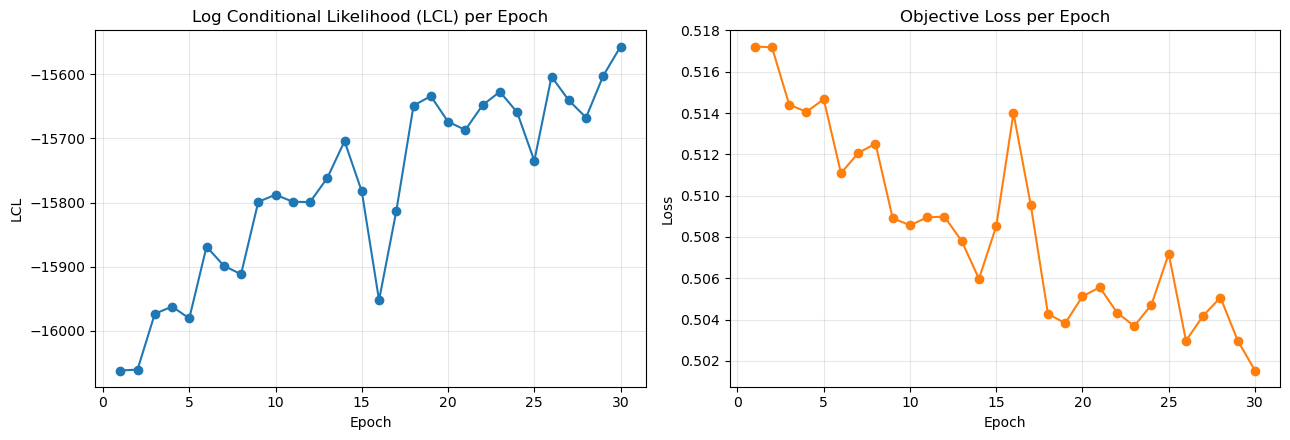

In [12]:
# ===== Stratified K-Fold Cross-Validation (Regularization Tuning) =====
configs = [
    {"penalty": None,         "learning_rate": 0.01, "reg_lambda": 0.0,  "l1_ratio": 0.5, "max_iter": 20},
    {"penalty": "l1",         "learning_rate": 0.01, "reg_lambda": 1e-5, "l1_ratio": 0.5, "max_iter": 20},
    {"penalty": "l1",         "learning_rate": 0.01, "reg_lambda": 1e-4, "l1_ratio": 0.5, "max_iter": 20},
    {"penalty": "l2",         "learning_rate": 0.01, "reg_lambda": 1e-5, "l1_ratio": 0.5, "max_iter": 20},
    {"penalty": "l2",         "learning_rate": 0.01, "reg_lambda": 1e-4, "l1_ratio": 0.5, "max_iter": 20},
    {"penalty": "elasticnet", "learning_rate": 0.01, "reg_lambda": 1e-5, "l1_ratio": 0.5, "max_iter": 20},
    {"penalty": "elasticnet", "learning_rate": 0.01, "reg_lambda": 1e-4, "l1_ratio": 0.5, "max_iter": 20},
]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_records = []
best_f1 = -1.0
best_config = None

for cfg in configs:
    fold_accs = []
    fold_f1s = []
    for train_idx, val_idx in skf.split(X_tr, y_tr):
        model = LogisticRegression(**cfg, random_state=RANDOM_STATE)
        model.fit(X_tr[train_idx], y_tr[train_idx])

        # Evaluasi murni pada sampel asli (non-SMOTE)
        fold_orig = orig_tr[val_idx]
        preds = model.predict(X_tr[val_idx][fold_orig])
        y_true = y_tr[val_idx][fold_orig]

        fold_accs.append(accuracy_score(y_true, preds))
        fold_f1s.append(f1_score(y_true, preds, average="macro"))

    mean_acc = float(np.mean(fold_accs))
    mean_f1 = float(np.mean(fold_f1s))
    std_f1 = float(np.std(fold_f1s))

    cv_records.append({
        "penalty": str(cfg["penalty"]),
        "reg_lambda": cfg["reg_lambda"],
        "learning_rate": cfg["learning_rate"],
        "mean_accuracy": mean_acc,
        "mean_macro_f1": mean_f1,
        "std_macro_f1": std_f1,
    })

    print(
        f"[LogReg | penalty={str(cfg['penalty']):10s}, lr={cfg['learning_rate']}, lambda={cfg['reg_lambda']:<6g}] -> "
        f"Mean Acc: {mean_acc:.5f} | Mean Macro F1: {mean_f1:.5f} (±{std_f1:.5f})"
    )

    if mean_f1 > best_f1:
        best_f1 = mean_f1
        best_config = cfg.copy()

cv_results_df = pd.DataFrame(cv_records).sort_values(by="mean_macro_f1", ascending=False).reset_index(drop=True)
print(f"\nKonfigurasi terbaik: {best_config} (CV Mean Macro F1: {best_f1:.5f})")

# ===== Fit Best Model on Full Training Split =====
final_logreg = LogisticRegression(
    learning_rate=best_config["learning_rate"],
    max_iter=30,
    penalty=best_config["penalty"],
    reg_lambda=best_config["reg_lambda"],
    l1_ratio=best_config["l1_ratio"],
    random_state=RANDOM_STATE,
)
final_logreg.fit(X_tr, y_tr)

val_preds = final_logreg.predict(X_val[orig_val])
val_acc = accuracy_score(y_val[orig_val], val_preds)
val_f1 = f1_score(y_val[orig_val], val_preds, average="macro")
print(f"Validation Hold-out (Original) -> Accuracy: {val_acc:.5f} | Macro F1: {val_f1:.5f}")

# ===== Plot Training Convergence =====
epochs = range(1, final_logreg.n_iter_ + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs, final_logreg.lcl_history_, marker="o", color="tab:blue")
axes[0].set_title("Log Conditional Likelihood (LCL) per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("LCL")
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs, final_logreg.loss_history_, marker="o", color="tab:orange")
axes[1].set_title("Objective Loss per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

=== Perbandingan Kinerja pada Validation Hold-out (Sampel Asli) ===
                             Model  Accuracy  Precision   Recall  F1 (Canceled=1)  Macro F1
LogisticRegression (Scratch - SGA)  0.751531   0.603034 0.711940         0.652977  0.729733
 LogisticRegression (Scikit-Learn)  0.756677   0.607564 0.731343         0.663732  0.736550

Prediction Agreement: 98.41% | Weight Cosine Similarity: 0.99992

--- Classification Report: LogisticRegression (Scratch) ---
              precision    recall  f1-score   support

           0     0.8455    0.7709    0.8065      2741
           1     0.6030    0.7119    0.6530      1340

    accuracy                         0.7515      4081
   macro avg     0.7243    0.7414    0.7297      4081
weighted avg     0.7659    0.7515    0.7561      4081

--- Classification Report: LogisticRegression (Scikit-Learn) ---
              precision    recall  f1-score   support

           0     0.8541    0.7691    0.8094      2741
           1     0.6076    0

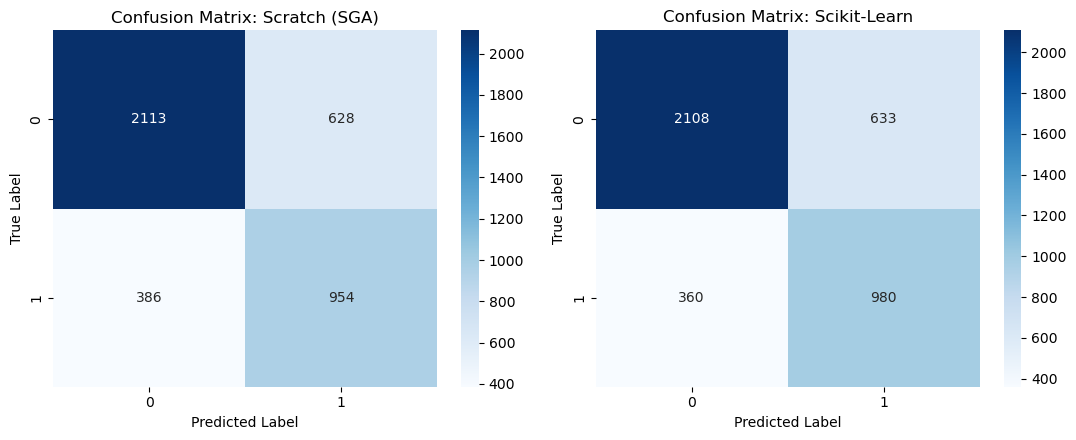

In [13]:
# ===== Perbandingan Model From Scratch vs Scikit-Learn =====
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

sklearn_logreg = SklearnLogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
sklearn_logreg.fit(X_tr, y_tr)

y_val_orig = y_val[orig_val]
X_val_orig = X_val[orig_val]
scratch_val_preds = final_logreg.predict(X_val_orig)
sk_val_preds = sklearn_logreg.predict(X_val_orig)

def _eval_metrics(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 (Canceled=1)": f1_score(y_true, y_pred, zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

comparison_df = pd.DataFrame([
    _eval_metrics("LogisticRegression (Scratch - SGA)", y_val_orig, scratch_val_preds),
    _eval_metrics("LogisticRegression (Scikit-Learn)", y_val_orig, sk_val_preds),
])

print("=== Perbandingan Kinerja pada Validation Hold-out (Sampel Asli) ===")
print(comparison_df.to_string(index=False))

agreement = (scratch_val_preds == sk_val_preds).mean() * 100.0
w_scratch = final_logreg.coef_
w_sklearn = sklearn_logreg.coef_.ravel()
cos_sim = float(np.dot(w_scratch, w_sklearn) / (np.linalg.norm(w_scratch) * np.linalg.norm(w_sklearn)))
print(f"\nPrediction Agreement: {agreement:.2f}% | Weight Cosine Similarity: {cos_sim:.5f}")

print("\n--- Classification Report: LogisticRegression (Scratch) ---")
print(classification_report(y_val_orig, scratch_val_preds, digits=4))
print("--- Classification Report: LogisticRegression (Scikit-Learn) ---")
print(classification_report(y_val_orig, sk_val_preds, digits=4))

# ===== Visualisasi Confusion Matrix Berdampingan =====
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.heatmap(confusion_matrix(y_val_orig, scratch_val_preds), annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion Matrix: Scratch (SGA)")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

sns.heatmap(confusion_matrix(y_val_orig, sk_val_preds), annot=True, fmt="d", cmap="Blues", ax=axes[1])
axes[1].set_title("Confusion Matrix: Scikit-Learn")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()

## Submission

In [ ]:
# bikin submisi yang reproducible